# **Bengaluru House Data: Analysis and Regression Model**


---


This project explores regression techniques applied to the **Bengaluru House Price dataset**: a real-world, messy dataset containing missing values, inconsistent formats, outliers, and high-cardinality categorical variables.

The goal is to predict house prices using three regression approaches, all implemented from scratch using NumPy only: **Multiple Linear Regression via Gradient Descent**, **Simple Linear Regression (Numerical View)**, and **Simple Linear Regression (Statistical View)**. Each model is extended to support optional **Ridge (L2)** and **Lasso (L1)** regularization. Results are compared across all model specifications using R² and Adjusted R².







In [139]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder , StandardScaler
import plotly.express as px

# **Exploratory Data Analysis (EDA)**
### Initial Data Inspection
Loading the dataset and reviewing basic properties such as shape, data types, and descriptive statistics to understand the feature distributions.

### Data Quality Audit
Identifying missing values and duplicate records across the features to determine the necessary cleaning steps.

### Visualizing Feature Relationships
Exploring correlations and distributions through plots to identify patterns and potential outliers in the housing data.

In [140]:
df= pd.read_csv(r"Bengaluru_House_Data.csv")

In [141]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [142]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


In [143]:
df.shape

(13320, 9)

In [144]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [145]:
df.describe(include=["object", "str"])

,area_type,availability,location,size,society,total_sqft
count,13320,13320,13319,13304,7818,13320
unique,4,81,1305,31,2688,2117
top,Super built-up Area,Ready To Move,Whitefield,2 BHK,GrrvaGr,1200
freq,8790,10581,540,5199,80,843


In [146]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [147]:
df.duplicated().sum()

np.int64(529)

**We begin by exploring the distribution of the target variable `price` and examining correlations between features.**

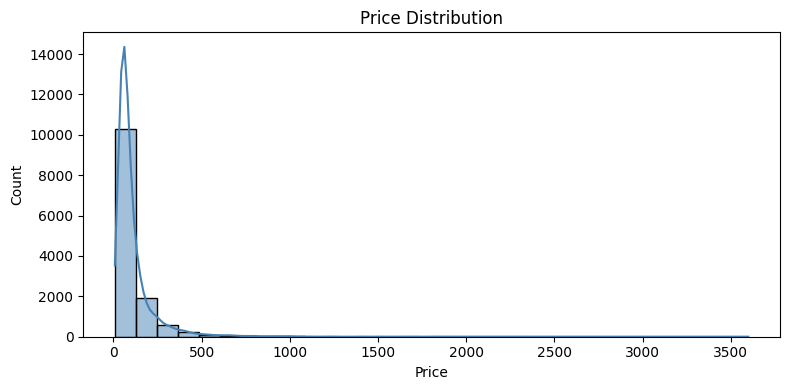

In [148]:
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=30, kde=True, color='steelblue')
plt.title('Price Distribution')
plt.xlabel('Price')
plt.tight_layout()
plt.show()

In [149]:
fig = px.histogram(
    df,
    x='price',
    nbins=30,
    title='Price Distribution',
    marginal='box' 
)

fig.update_layout(
    xaxis_title="Price",
    yaxis_title="Count"
)

fig.show()

**The histogram shows that the `price` variable is right-skewed, with most properties concentrated in the lower price range and a small number of properties having very high prices. This indicates the presence of extreme values, which may represent luxury properties rather than errors.**

<Axes: >

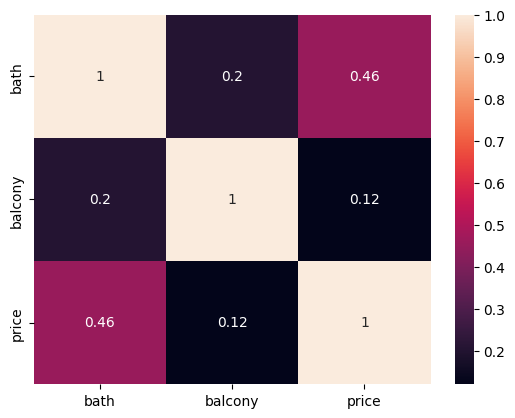

In [150]:
sns.heatmap(df.corr(numeric_only=True), annot= True)

**The correlation heatmap indicates a moderate positive relationship between `bath` and `price`, suggesting that properties with more bathrooms are generally more expensive. In contrast, the correlation between `balcony` and `price` is weak, indicating a limited impact on price.**


---



### **Correlation Heatmap (Interactive)**

This heatmap shows the correlation between all numerical variables in the dataset.

- Strong positive correlation (close to +1) indicates that as one variable increases, the other also increases.
- Strong negative correlation (close to -1) indicates an inverse relationship.
- Values near 0 indicate weak or no linear relationship.

From this heatmap, we can identify which features are most strongly related to the target variable (price), which helps in selecting predictors for regression models.

This step is essential for understanding multicollinearity and feature importance before modeling.

In [151]:
corr = df.corr(numeric_only=True)
fig = px.imshow(corr,text_auto=True,color_continuous_scale='RdBu_r',title="Interactive Correlation Heatmap")
fig.show()

# **Data Preprocessing**




## Removing Duplicates

In [152]:
df=df.drop_duplicates()

In [153]:
df.duplicated().sum()

np.int64(0)

## Handling Inconsistent Format

In [154]:
df['Number_of_rooms'] = df['size'].str.extract(r'(\d+)')

In [155]:
df = df.drop('size', axis=1)

In [156]:
print(df['Number_of_rooms'].dtype)

str


In [157]:
df['Number_of_rooms'] = pd.to_numeric(df['Number_of_rooms'], errors='coerce')

In [158]:
print(df['Number_of_rooms'].dtype)

float64


**The `size` column contains inconsistent formats such as `'2 BHK'`, `'3 Bedroom'`, and range values like `'2-4 BHK'`. We extract only the numeric part and handle range values by averaging. The `total_sqft` column has similar issues and is cleaned the same way. The `availability` column is simplified to a binary flag: `Available` or `Not Available`.**

In [159]:
def clean_size(x):
    try:
        x = str(x)
        if '-' in x:
            nums = x.split('-')
            nums = [float(n.strip()) for n in nums]
            return sum(nums) / len(nums)
        else:
            return float(x.split()[0])
    except:
        return None
df['total_sqft'] = df['total_sqft'].apply(clean_size)

In [160]:
df['availability'] = df['availability'].apply(lambda x: 'Available' if x == 'Ready To Move' else 'Not Available')

## Handling Missing values

In [161]:
df.dropna(subset=['location', 'bath', 'balcony','total_sqft', 'Number_of_rooms'], inplace=True)

In [162]:
df = df.drop(columns=['society'])

41.3%  of values are missing, so dropping society is the best choice

In [163]:
df.isnull().sum()

area_type          0
availability       0
location           0
total_sqft         0
bath               0
balcony            0
price              0
Number_of_rooms    0
dtype: int64

## Outliers Handling & Skewness Transformation
We detect and handle outliers using the IQR method, then apply log transformation to correct right-skewed distributions before modeling.


IQR outliers in bath: 824


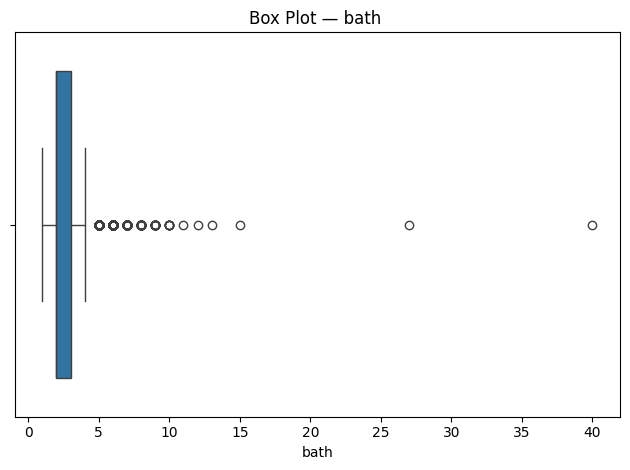

In [164]:
Q1 = df['bath'].quantile(0.25)
Q3 = df['bath'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_iqr = df[(df['bath'] < lower) | (df['bath'] > upper)]
print(f'IQR outliers in bath: {len(outliers_iqr)}')
sns.boxplot(data=df,x='bath')
plt.title('Box Plot — bath ')
plt.xlabel('bath')
plt.tight_layout()
plt.show()

In [165]:
Q1 = df['bath'].quantile(0.25)
Q3 = df['bath'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers_iqr = df[(df['bath'] < lower) | (df['bath'] > upper)]

print(f'IQR outliers in bath: {len(outliers_iqr)}')

fig = px.box(
    df,
    x='bath',
    points='outliers', 
    title='Box Plot — bath (Interactive)'
)

fig.add_vline(x=lower, line_dash="dash", line_color="red", annotation_text="Lower Bound")
fig.add_vline(x=upper, line_dash="dash", line_color="red", annotation_text="Upper Bound")

fig.update_layout(
    xaxis_title="bath",
)

fig.show()

IQR outliers in bath: 824


In [166]:
df = df[df['bath'] <= 10]

IQR outliers in bath: 818


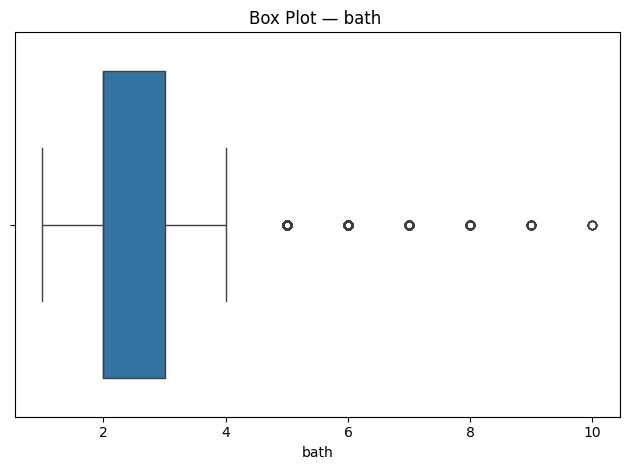

In [167]:
Q1 = df['bath'].quantile(0.25)
Q3 = df['bath'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_iqr = df[(df['bath'] < lower) | (df['bath'] > upper)]
print(f'IQR outliers in bath: {len(outliers_iqr)}')
sns.boxplot(data=df,x='bath')
plt.title('Box Plot — bath ')
plt.xlabel('bath')
plt.tight_layout()
plt.show()

In [168]:
Q1 = df['bath'].quantile(0.25)
Q3 = df['bath'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers_iqr = df[(df['bath'] < lower) | (df['bath'] > upper)]
print(f'IQR outliers in bath: {len(outliers_iqr)}')

fig = px.box(
    df,
    x='bath',
    points='outliers',
    title='Box Plot — bath (Interactive)'
)

fig.add_vline(x=lower, line_dash="dash", line_color="red")
fig.add_vline(x=upper, line_dash="dash", line_color="red")

fig.show()

IQR outliers in bath: 818


**Outliers in the `bath` variable were detected using the IQR method. Extremely high values were considered unrealistic and were removed, while the remaining values were kept as they may represent valid large properties.**

IQR outliers in price: 1140


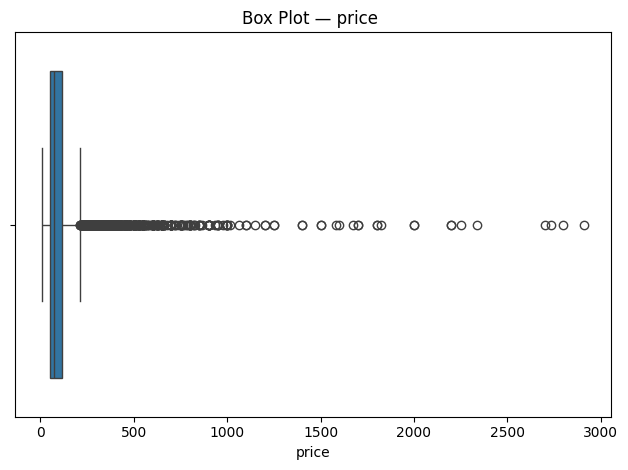

In [169]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_iqr = df[(df['price'] < lower) | (df['price'] > upper)]
print(f'IQR outliers in price: {len(outliers_iqr)}')
sns.boxplot(data=df,x='price')
plt.title('Box Plot — price ')
plt.xlabel('price')
plt.tight_layout()
plt.show()

In [170]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers_iqr = df[(df['price'] < lower) | (df['price'] > upper)]
print(f'IQR outliers in price: {len(outliers_iqr)}')

fig = px.box(
    df,
    x='price',
    points='outliers',
    title='Box Plot — Price (Interactive)'
)

fig.add_vline(x=lower, line_dash="dash", line_color="red")
fig.add_vline(x=upper, line_dash="dash", line_color="red")

fig.update_layout(xaxis_title="Price")

fig.show()

IQR outliers in price: 1140


**Outliers in the `price` variable were detected using the IQR method. The values were kept as they may represent valid large properties.**

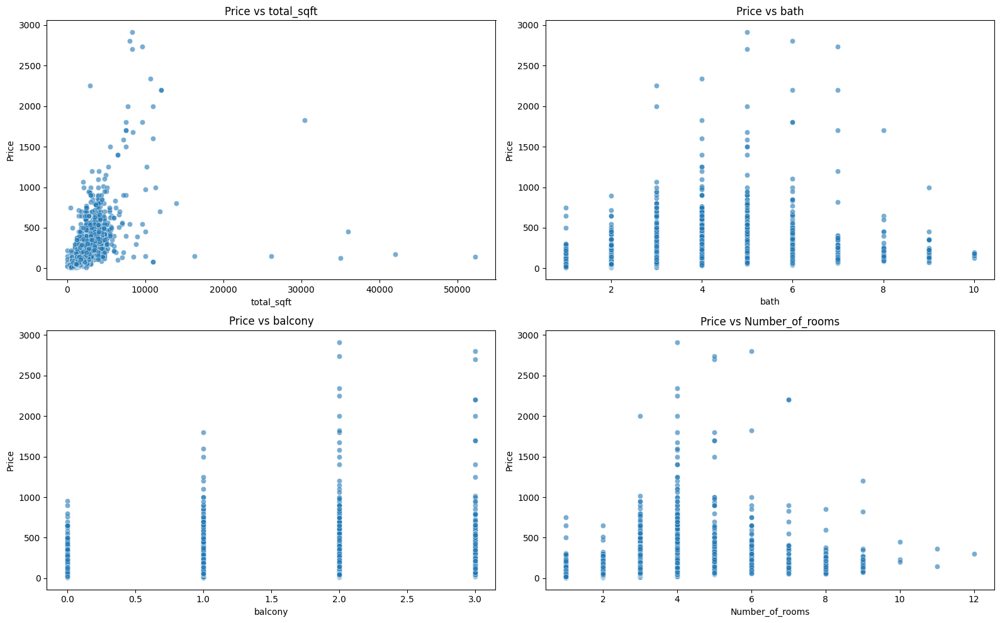

In [171]:
features = ['total_sqft', 'bath', 'balcony', 'Number_of_rooms']

plt.figure(figsize=(16, 10))

for i, col in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.scatterplot(x=df[col], y=df['price'], alpha=0.6)
    plt.title(f'Price vs {col}')
    plt.xlabel(col)
    plt.ylabel('Price')

plt.tight_layout()
plt.show()

The scatter plots indicate that price has a strong positive relationship with `total_sqft` and a moderate relationship with `bath` and `Number_of_rooms`, while `balcony` has a weaker impact. Although some extreme values are observed, they align with the general trend of the data, suggesting that these values may represent genuine high-priced properties. Therefore, outliers were not removed automatically without further consideration.

### **Interactive Scatter Plot (Feature vs Price)**

This interactive plot allows us to explore the relationship between individual features and the target variable (price).

- A positive trend suggests that the feature increases with price.
- A weak or scattered pattern indicates a weak relationship.
- The regression line (trendline) helps visualize the linear relationship.

From this analysis, we observe that features like total_sqft show a strong positive relationship with price, making them good candidates for regression modeling.

In [265]:
def interactive_scatter(x_col):
    fig = px.scatter(
        df,
        x=x_col,
        y='price',
        trendline='ols',
        title=f'Price vs {x_col} (Interactive)',
        opacity=0.5
    )
    fig.show()

In [267]:
interactive_scatter('total_sqft')
interactive_scatter('bath')
interactive_scatter('Number_of_rooms')
interactive_scatter('balcony')

In [172]:
import plotly.graph_objects as go

numeric_features = ['total_sqft', 'bath', 'balcony', 'Number_of_rooms']

fig = go.Figure()

for col in numeric_features:
    fig.add_trace(go.Scatter(
        x=df[col],
        y=df['price'],
        mode='markers',
        name=col,
        visible=(col == 'total_sqft'),
        opacity=0.5
    ))

buttons = []
for i, col in enumerate(numeric_features):
    visible = [j == i for j in range(len(numeric_features))]
    buttons.append(dict(
        label=col,
        method='update',
        args=[{'visible': visible},
              {'title': f'Price vs {col}'}]
    ))

fig.update_layout(
    title='Price vs total_sqft',
    xaxis_title='Feature',
    yaxis_title='log(price)',
    updatemenus=[dict(
        active=0,
        buttons=buttons,
        direction='down',
        x=0.1,
        y=1.15
    )]
)

fig.show()

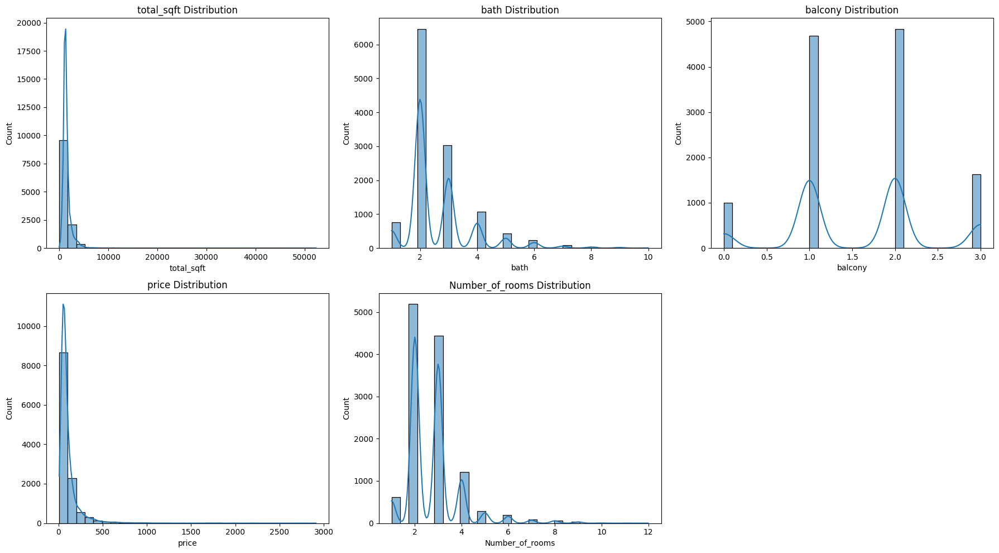

In [173]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

n = len(numeric_cols)
n_cols = 3
n_rows = (n + n_cols - 1) // n_cols

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df[col], bins=30, kde=True)
    plt.xlabel(col)
    plt.title(f"{col} Distribution")

plt.tight_layout()
plt.show()

In [174]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    fig = px.histogram(
        df,
        x=col,
        nbins=30,
        title=f"{col} Distribution",
        marginal="box",  
        opacity=0.7
    )
    
    fig.update_layout(
        xaxis_title=col,
        yaxis_title="Count"
    )
    
    fig.show()

### log1p tranformation
Both `price` and `total_sqft` are right-skewed. We apply `log1p` transformation to compress large values and normalize the distributions, which improves gradient descent convergence and model performance.

In [175]:
df['total_sqft'] = np.log1p(df['total_sqft'])
df['price'] = np.log1p(df['price'])

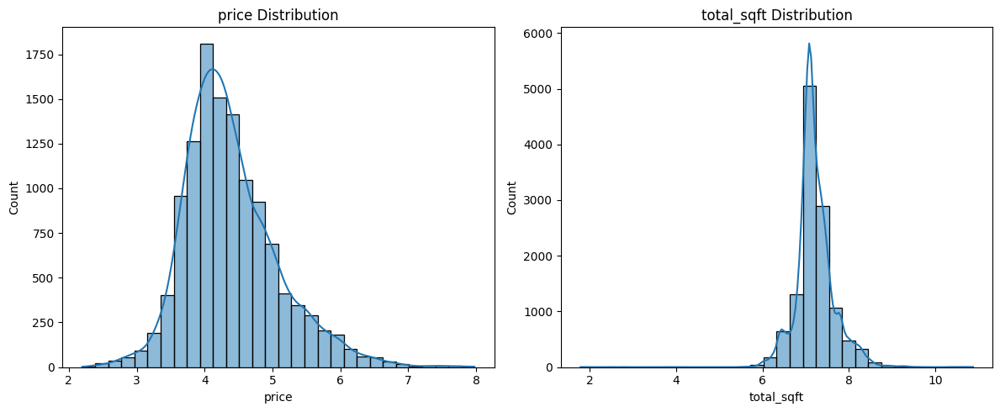

In [176]:
cols_to_check = ['price', 'total_sqft']

plt.figure(figsize=(12, 5))

for i, col in enumerate(cols_to_check, 1):
    plt.subplot(1, 2, i)
    sns.histplot(df[col], bins=30, kde=True)
    plt.xlabel(col)
    plt.title(f"{col} Distribution")

plt.tight_layout()
plt.show()

In [177]:
cols_to_check = ['price', 'total_sqft']

for col in cols_to_check:
    fig = px.histogram(
        df,
        x=col,
        nbins=30,
        title=f"{col} Distribution",
        marginal="box",   
        opacity=0.75
    )
    
    fig.update_layout(
        xaxis_title=col,
        yaxis_title="Count"
    )
    
    fig.show()


**"After applying Log Transformation to `price` and `total_sqft` shifted the distribution successfully from right-skewed to a normal distribution (Gaussian-like)**

## Train-Test Split into 80% : 20%


---


### Data Partitioning
Defining features (X) and target (y), then splitting the data into training and testing sets.

In [178]:
X = df.drop('price', axis=1)
y = df['price']

x_train, x_test, y_train, y_test = train_test_split( X, y, test_size=0.2,random_state=42)

In [179]:
print("x_train shape:", x_train.shape)
print("x_test shape :", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

x_train shape: (9709, 7)
x_test shape : (2428, 7)
y_train shape: (9709,)
y_test shape : (2428,)


## Encoding Categorical Variables
`location` has hundreds of unique values so **target encoding** is used; replacing each location with the mean price of that location in the training set. `area_type` and `availability` have few categories so **one-hot encoding** is applied.

In [180]:
for col in df.select_dtypes(include=["object", "str"]).columns:
    print(f"{col} : {df[col].nunique()}")
    print()


area_type : 4

availability : 2

location : 1255



In [181]:
loc_means = y_train.groupby(x_train['location']).mean()
x_train['location_enc'] = x_train['location'].map(loc_means)
x_test['location_enc']  = x_test['location'].map(loc_means)

x_train['location_enc'] = x_train['location_enc'].fillna(y_train.mean())
x_test['location_enc']  = x_test['location_enc'].fillna(y_train.mean())

x_train = x_train.drop(columns=['location'])
x_test  = x_test.drop(columns=['location'])

In [182]:
categorical_cols = ['area_type', 'availability']

encoder = OneHotEncoder(handle_unknown='ignore',sparse_output=False)

train_encoded = encoder.fit_transform(x_train[categorical_cols])
test_encoded = encoder.transform(x_test[categorical_cols])

In [183]:
encoded_cols = encoder.get_feature_names_out(categorical_cols)

# convert encoded arrays to DataFrames
train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_cols,
    index=x_train.index
)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_cols,
    index=x_test.index
)

In [184]:
# drop original categorical columns and add encoded columns
x_train = pd.concat(
    [x_train.drop(columns=categorical_cols), train_encoded_df],
    axis=1
)

x_test = pd.concat(
    [x_test.drop(columns=categorical_cols), test_encoded_df],
    axis=1
)

In [185]:
print("Encoded x_train shape:", x_train.shape)
print("Encoded x_test shape :", x_test.shape)
x_train.head()

Encoded x_train shape: (9709, 11)
Encoded x_test shape : (2428, 11)


,total_sqft,bath,balcony,Number_of_rooms,location_enc,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Available,availability_Not Available
2565,7.215975,2.0,1.0,3.0,4.077642,0.0,0.0,0.0,1.0,1.0,0.0
32,7.473637,2.0,2.0,3.0,4.867744,0.0,0.0,0.0,1.0,1.0,0.0
8902,7.824446,5.0,2.0,4.0,4.754339,0.0,0.0,1.0,0.0,1.0,0.0
6019,7.090910,2.0,2.0,3.0,4.180327,0.0,0.0,0.0,1.0,0.0,1.0
4404,6.945051,2.0,1.0,2.0,3.618457,0.0,0.0,0.0,1.0,1.0,0.0


## Scalling
Numerical features are standardized using `StandardScaler`, fitted on training data only, then applied to both train and test sets to prevent leakage.

In [186]:
scaled_numeric_cols = ['bath', 'balcony', 'total_sqft', 'Number_of_rooms', 'location_enc']

scaler = StandardScaler()

x_train[scaled_numeric_cols] = scaler.fit_transform(x_train[scaled_numeric_cols])
x_test[scaled_numeric_cols] = scaler.transform(x_test[scaled_numeric_cols])

In [187]:
x_train

,total_sqft,bath,balcony,Number_of_rooms,location_enc,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Available,availability_Not Available
2565,0.000485,-0.540725,-0.704740,0.219653,-0.675338,0.0,0.0,0.0,1.0,1.0,0.0
32,0.580511,-0.540725,0.510593,0.219653,1.036118,0.0,0.0,0.0,1.0,1.0,0.0
8902,1.370219,2.028139,0.510593,1.097996,0.790470,0.0,0.0,1.0,0.0,1.0,0.0
6019,-0.281050,-0.540725,0.510593,0.219653,-0.452909,0.0,0.0,0.0,1.0,0.0,1.0
4404,-0.609394,-0.540725,-0.704740,-0.658689,-1.669987,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
13119,3.584801,2.884427,-0.704740,1.097996,4.396390,0.0,0.0,1.0,0.0,1.0,0.0
5585,-0.380690,-0.540725,-0.704740,-0.658689,1.205702,1.0,0.0,0.0,0.0,1.0,0.0
5808,-0.262384,-0.540725,-0.704740,-0.658689,-1.087509,0.0,0.0,0.0,1.0,1.0,0.0
906,-1.538464,-1.397014,-0.704740,-1.537031,-3.247106,0.0,0.0,0.0,1.0,1.0,0.0


In [188]:
y_train

2565     4.098834
32       4.820282
8902     5.505332
6019     4.338597
4404     3.618457
           ...   
13119    6.552508
5585     4.094345
5808     4.007333
906      2.890372
7875     3.772761
Name: price, Length: 9709, dtype: float64

## Best Single Predictor Selection

After preprocessing (log transformation, encoding, and scaling), we compute the absolute correlation of each feature with log(price) to confirm which single predictor is most appropriate for the Numerical and Statistical View models.

In [189]:
# Correlation of all features with log(price) after preprocessing
corr_with_price = x_train.corrwith(y_train).abs().sort_values(ascending=False)

print("Absolute Correlation with log(price) — after preprocessing:")
print(corr_with_price.to_string())
print(f"\nBest single predictor: {corr_with_price.index[0]}")
print(f"Correlation value    : {corr_with_price.iloc[0]:.4f}")

Absolute Correlation with log(price) — after preprocessing:
total_sqft                        0.744980
location_enc                      0.668434
bath                              0.646907
Number_of_rooms                   0.597729
area_type_Plot  Area              0.349948
area_type_Super built-up  Area    0.229473
balcony                           0.193368
availability_Available            0.082396
availability_Not Available        0.082396
area_type_Built-up  Area          0.034686
area_type_Carpet  Area            0.023354

Best single predictor: total_sqft
Correlation value    : 0.7450


# **Model Fitting (Implemented from scratch)**

## **Simple Linear Regression: Numerical View**

In this section, we implement **Simple Linear Regression** from scratch using NumPy only, taking a purely **numerical / algebraic approach** via the OLS Normal Equations. We also extend the class to support **Ridge** and **Lasso** regularization as optional parameters, both defaulting to no penalty.

This approach solves for the optimal coefficients **analytically** in one step using the closed-form solution.

In [190]:
class SimpleLinearRegressionNumericalView:

    def __init__(self, regularization=None, lambda_=0):
        """
        Initializes the SimpleLinearRegressionNumericalView model.
        """
        self.a0 = None
        self.a1 = None
        self.SSE = None
        self.MSE = None
        self.RMSE = None
        self.regularization = regularization
        self.lambda_ = lambda_

    def fit(self, X, y, show_steps=True):
        X = np.asarray(X, dtype=float).reshape(-1)
        y = np.asarray(y, dtype=float).reshape(-1)
        n = len(X)

        # Step 1: Summations
        Sx  = np.sum(X)
        Sy  = np.sum(y)
        Sxx = np.sum(X**2)
        Sxy = np.sum(X * y)

        if show_steps:
            print("=== Step 1: Summations ===")
            print(f"n = {n}")
            print(f"ΣX = {Sx:,.2f}, ΣY = {Sy:,.2f}")
            print(f"ΣX² = {Sxx:,.2f}, ΣXY = {Sxy:,.2f}\n")

        # Step 2: OLS Normal Equations
        A = np.array([[n, Sx], [Sx, Sxx]], dtype=float)
        B = np.array([Sy, Sxy], dtype=float)

        if show_steps:
            print("=== Step 2: OLS (Normal Equations) ===")
            print("Equations Form:")
            print(f"1) {n}*a0 + {Sx:.2f}*a1 = {Sy:.2f}")
            print(f"2) {Sx:.2f}*a0 + {Sxx:.2f}*a1 = {Sxy:.2f}\n")

            print("Matrix Form [A][X] = [B]:")
            print(f"[[ {n:<5}  {Sx:<8.2f} ]] [a0]   [[ {Sy:<8.2f} ]]")
            print(f"[[ {Sx:<5.2f}  {Sxx:<8.2f} ]] [a1] = [[ {Sxy:<8.2f} ]]\n")

        self.a0, self.a1 = np.linalg.solve(A, B)
        label = "OLS (Normal)"

        if show_steps:
            print(f"Solution:")
            print(f"a0 (Intercept) = {self.a0:.4f}")
            print(f"a1 (Slope)     = {self.a1:.4f}\n")

        # RIDGE
        if self.regularization == 'ridge' and self.lambda_ > 0:
            ridge_penalty = n * self.lambda_

            if show_steps:
                print("=== Ridge Regression – Numerical View ===")
                print("\nStep 2: Define Objective Loss")
                print("Loss = SSE + nλa1²")
                print("Loss = Σ(yi - a0 - a1 xi)^2 + nλa1²\n")
                print("Step 3: Compute Summations & Penalties")
                print(f"λ = {self.lambda_}")
                print(f"nλ = {ridge_penalty}")
                print(f"Σxi = {Sx:.2f}")
                print(f"Σyi = {Sy:.2f}")
                print(f"Σxi² = {Sxx:.2f}")
                print(f"Σxiyi = {Sxy:.2f}\n")
                print("Step 4: Modified Normal Equations")
                print(f"{Sy:.2f} = {n} a0 + {Sx:.2f} a1")
                print(f"{Sxy:.2f} = {Sx:.2f} a0 + ({Sxx:.2f} + {ridge_penalty:.2f}) a1\n")
                print("Step 5: Matrix Form")
                print("[[ n        Σxi      ]] [a0] = [ Σyi   ]")
                print("[[ Σxi     Σxi² + nλ ]] [a1] = [ Σxiyi ]\n")

            A_ridge = np.array([[n, Sx], [Sx, Sxx + ridge_penalty]], dtype=float)
            self.a0, self.a1 = np.linalg.solve(A_ridge, B)
            label = f"Ridge (λ={self.lambda_})"

            if show_steps:
                print("Step 6: Solve the System")
                print(f"a0 = {self.a0:.4f}")
                print(f"a1 (shrunk) = {self.a1:.4f}\n")

        # LASSO
        elif self.regularization == 'lasso' and self.lambda_ > 0:
            sign = np.sign(Sxy)

            if show_steps:
                print("=== Lasso Regression - Numerical View ===")

                print("\nStep 2: Define Objective Loss")
                print("Loss = SSE + nλ|a1|")
                print("Loss = Σ(yi - a0 - a1 xi)^2 + nλ|a1|\n")

                print("Step 3: Idea of Lasso")
                print("→ Lasso adds penalty on absolute value |a1|")
                print("→ Encourages sparsity (a1 can become 0)")
                print("→ Feature selection effect\n")

                print("Step 4: Soft Thresholding Rule")
                print("Subgradient sets: -2·SXY + 2·a1·SXX + nλ·sign(a1) = 0")
                print("→ Equivalent form: a1 = sign(SXY) * max(|SXY| - nλ/2, 0) / SXX")
                print("→ Same as Statistical View: sign(a1_ols) * max(|a1_ols| - nλ/(2·SXX), 0)")
                print("→ Both formulas are mathematically identical — different notation only\n")
 
                a1_ols = Sxy / Sxx
                print(f"a1_ols (SXY/SXX)     = {a1_ols:.6f}")
                print(f"|a1_ols|             = {abs(a1_ols):.6f}")
                print(f"threshold nλ/(2·SXX) = {(n * self.lambda_)/(2 * Sxx):.6f}")
                print(f"[Same as nλ/2 / SXX  = {(n * self.lambda_/2) / Sxx:.6f}\n")

            Sxy_shrunk = max(abs(Sxy) - (n * self.lambda_ / 2), 0)
            self.a1    = sign * Sxy_shrunk / Sxx
            self.a0    = (Sy - self.a1 * Sx) / n
            label      = f"Lasso (λ={self.lambda_})"

            if show_steps:
                print("Step 5: After Shrinkage")
                print(f"New a1 = {self.a1:.6f}")

                if self.a1 == 0:
                    print("a1 became ZERO → feature removed")

                print("\nStep 6: Recalculate Intercept")
                print("a0 = (Σy - a1 Σx) / n")
                print(f"a0 = {self.a0:.4f}\n")

        # METRICS
        y_hat    = self.predict(X)
        self.SSE = np.sum((y - y_hat) ** 2)
        self.MSE = self.SSE / n
        self.RMSE = np.sqrt(self.MSE)

        if show_steps:
            print(f"=== Final Model: {label} ===")
            print(f"ŷ = {self.a0:.4f} + {self.a1:.4f}x\n")
            print(f"SSE  = {self.SSE:,.2f}")
            print(f"MSE  = {self.MSE:,.2f}")
            print(f"RMSE = {self.RMSE:,.2f}")
            print("-" * 60)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float).reshape(-1)
        return self.a0 + self.a1 * X

    def r2_score(self, y_true, y_pred):
        """
        Computes R² (coefficient of determination).
        R² = 1 - (SS_residual / SS_total)
        Closer to 1.0 = better fit.
        """
        y_true = np.array(y_true)
        y_pred = np.array(y_pred)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        if ss_tot == 0:
            return 0
        return 1 - (ss_res / ss_tot)

    def plot(self, X_test, y_test, y_pred):
        """
        Plots Predicted vs Actual values and Residuals.

        Parameters:
        -----------
        X_test : array-like — feature values (for reference)
        y_test : array-like — actual target values
        y_pred : array-like — predicted target values
        """
        if self.a0 is None:
            raise ValueError('The model has not been fitted yet.')

        y_true    = np.array(y_test)
        y_pred    = np.array(y_pred)
        residuals = y_true - y_pred

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        # Plot 1: Predicted vs Actual
        axes[0].scatter(y_true, y_pred, alpha=0.4, color='blue', edgecolors='none', s=15, label='Data points')
        min_val = min(y_true.min(), y_pred.min())
        max_val = max(y_true.max(), y_pred.max())
        axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linewidth=1.5, label='Perfect prediction')
        axes[0].set_xlabel('Actual Price')
        axes[0].set_ylabel('Predicted Price')
        axes[0].set_title('Predicted vs Actual')
        axes[0].legend()
        axes[0].grid(True, alpha=0.2)

        # Plot 2: Residuals
        axes[1].scatter(y_pred, residuals, alpha=0.4, color='green', edgecolors='none', s=15, label='Residuals')
        axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
        axes[1].set_xlabel('Predicted Price')
        axes[1].set_ylabel('Residual (Actual - Predicted)')
        axes[1].set_title('Residual Plot')
        axes[1].legend()
        axes[1].grid(True, alpha=0.2)

        plt.tight_layout()
        plt.show()

print('Class defined successfully!')

Class defined successfully!


### **Interactive Residual Plot**

This plot shows the residuals (errors) of the model:

Residual = Actual − Predicted

- Ideally, residuals should be randomly scattered around zero.
- Patterns or shapes indicate model bias or missing relationships.
- Large spread indicates high error variance.

From the plot, we can assess:
- Model accuracy
- Presence of heteroscedasticity
- Whether a linear model is appropriate

This is a key diagnostic tool for evaluating regression models.

### **Interactive Predicted vs Actual Values**

This plot compares predicted values with actual values.

- Points close to the diagonal line indicate accurate predictions.
- The closer the points are to the line, the better the model.
- Large deviations indicate prediction errors.

This visualization helps evaluate how well the model generalizes to unseen data.

In [191]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

def plot_interactive(y_true, y_pred):
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    residuals = y_true - y_pred

    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=("Predicted vs Actual", "Residual Plot")
    )

    # Plot 1: Predicted vs Actual
    fig.add_trace(
        go.Scatter(x=y_true, y=y_pred, mode='markers', name='Predictions', opacity=0.5),
        row=1, col=1
    )

    # Perfect line
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())

    fig.add_trace(
        go.Scatter(x=[min_val, max_val], y=[min_val, max_val], mode='lines', name='Perfect Fit', line=dict(color='red')),
        row=1, col=1
    )

    # Plot 2: Residuals
    fig.add_trace(
        go.Scatter(x=y_pred, y=residuals, mode='markers', name='Residuals', opacity=0.5),
        row=1, col=2
    )

    fig.add_hline(y=0, line_dash="dash", line_color="red", row=1, col=2)

    # Layout
    fig.update_layout(
        title="Model Performance (Interactive)",
        showlegend=False,
        height=500
    )

    fig.update_xaxes(title_text="Actual Price", row=1, col=1)
    fig.update_yaxes(title_text="Predicted Price", row=1, col=1)

    fig.update_xaxes(title_text="Predicted Price", row=1, col=2)
    fig.update_yaxes(title_text="Residuals", row=1, col=2)

    fig.show()

## Data Setup for Numerical View

We use only the `total_sqft` feature (after scaling + standarized) since Simple Linear Regression takes a single predictor.

In [192]:
X_train_num = x_train['total_sqft']
y_train_num = y_train

X_test_num = x_test['total_sqft']
y_test_num = y_test

## Plain OLS (Numerical)

In [193]:
num_model_plain = SimpleLinearRegressionNumericalView(regularization=None)
num_model_plain.fit(X_train_num, y_train_num, show_steps=True)
print('SSE:' , round(num_model_plain.SSE, 4))
print('MSE:' , round(num_model_plain.MSE, 4))
print('RMSE:' , round(num_model_plain.RMSE, 4))

y_pred_num_plain = num_model_plain.predict(X_test_num)
r2_num_plain = num_model_plain.r2_score(np.array(y_test_num), y_pred_num_plain)
print(f'Plain Numerical — R²: {r2_num_plain:.4f}')

=== Step 1: Summations ===
n = 9709
ΣX = -0.00, ΣY = 42,616.83
ΣX² = 9,709.00, ΣXY = 4,995.49

=== Step 2: OLS (Normal Equations) ===
Equations Form:
1) 9709*a0 + -0.00*a1 = 42616.83
2) -0.00*a0 + 9709.00*a1 = 4995.49

Matrix Form [A][X] = [B]:
[[ 9709   -0.00    ]] [a0]   [[ 42616.83 ]]
[[ -0.00  9709.00  ]] [a1] = [[ 4995.49  ]]

Solution:
a0 (Intercept) = 4.3894
a1 (Slope)     = 0.5145

=== Final Model: OLS (Normal) ===
ŷ = 4.3894 + 0.5145x

SSE  = 2,060.91
MSE  = 0.21
RMSE = 0.46
------------------------------------------------------------
SSE: 2060.9062
MSE: 0.2123
RMSE: 0.4607
Plain Numerical — R²: 0.5270


In [194]:
train_pred = num_model_plain.predict(X_train_num)
test_pred  = num_model_plain.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train_num)
y_test_original  = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Numerical Plain:")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Numerical Plain:
Train MSE (original scale): 17,044.40
Test MSE  (original scale): 9,858.82


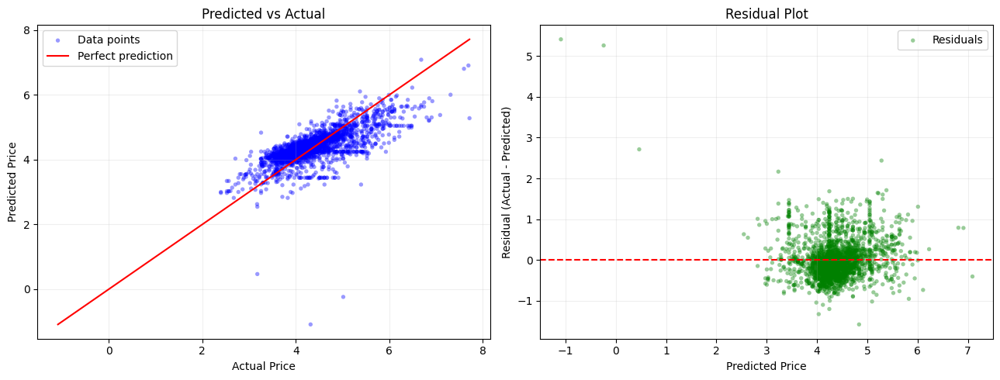

In [195]:
num_model_plain.plot(X_test_num, y_test_num, y_pred_num_plain)

In [196]:
plot_interactive(y_test_num, y_pred_num_plain)

## Ridge Regression (Numerical + L2)

In [197]:
num_model_ridge = SimpleLinearRegressionNumericalView(regularization='ridge', lambda_=0.05)
num_model_ridge.fit(X_train_num, y_train_num, show_steps=True)
print('SSE:' , round(num_model_ridge.SSE, 4))
print('MSE:' , round(num_model_ridge.MSE, 4))
print('RMSE:' , round(num_model_ridge.RMSE, 4))

y_pred_num_ridge = num_model_ridge.predict(X_test_num)
r2_num_ridge = num_model_ridge.r2_score(np.array(y_test_num), y_pred_num_ridge)
print(f'Ridge Numerical — R²: {r2_num_ridge:.4f}')

=== Step 1: Summations ===
n = 9709
ΣX = -0.00, ΣY = 42,616.83
ΣX² = 9,709.00, ΣXY = 4,995.49

=== Step 2: OLS (Normal Equations) ===
Equations Form:
1) 9709*a0 + -0.00*a1 = 42616.83
2) -0.00*a0 + 9709.00*a1 = 4995.49

Matrix Form [A][X] = [B]:
[[ 9709   -0.00    ]] [a0]   [[ 42616.83 ]]
[[ -0.00  9709.00  ]] [a1] = [[ 4995.49  ]]

Solution:
a0 (Intercept) = 4.3894
a1 (Slope)     = 0.5145

=== Ridge Regression – Numerical View ===

Step 2: Define Objective Loss
Loss = SSE + nλa1²
Loss = Σ(yi - a0 - a1 xi)^2 + nλa1²

Step 3: Compute Summations & Penalties
λ = 0.05
nλ = 485.45000000000005
Σxi = -0.00
Σyi = 42616.83
Σxi² = 9709.00
Σxiyi = 4995.49

Step 4: Modified Normal Equations
42616.83 = 9709 a0 + -0.00 a1
4995.49 = -0.00 a0 + (9709.00 + 485.45) a1

Step 5: Matrix Form
[[ n        Σxi      ]] [a0] = [ Σyi   ]
[[ Σxi     Σxi² + nλ ]] [a1] = [ Σxiyi ]

Step 6: Solve the System
a0 = 4.3894
a1 (shrunk) = 0.4900

=== Final Model: Ridge (λ=0.05) ===
ŷ = 4.3894 + 0.4900x

SSE  = 2,066.73
MSE

In [198]:
train_pred = num_model_ridge.predict(X_train_num)
test_pred  = num_model_ridge.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train_num)
y_test_original  = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Numerical Ridge (λ=0.05):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Numerical Ridge (λ=0.05):
Train MSE (original scale): 14,935.56
Test MSE  (original scale): 10,303.40


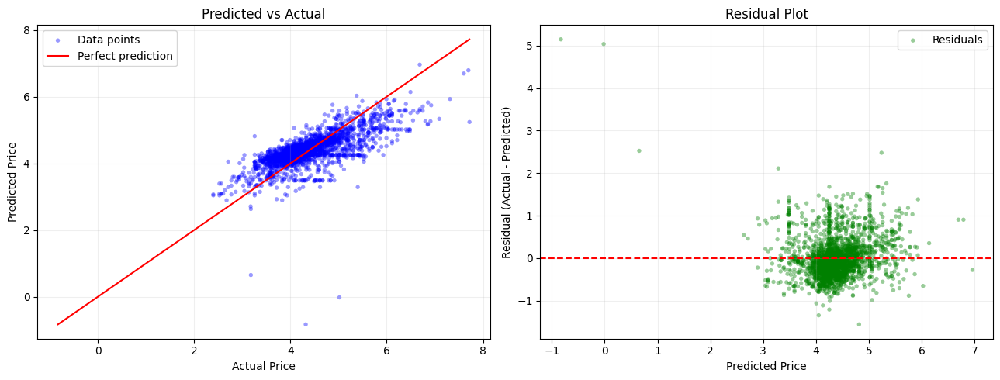

In [199]:
num_model_ridge.plot(X_test_num, y_test_num, y_pred_num_ridge)

In [200]:
plot_interactive(y_test_num, y_pred_num_ridge)

## Lasso Regression (Numerical + L1)

In [201]:
num_model_lasso = SimpleLinearRegressionNumericalView(regularization='lasso', lambda_=0.1)
num_model_lasso.fit(X_train_num, y_train_num, show_steps=True)
print('SSE:' , round(num_model_lasso.SSE, 4))
print('MSE:' , round(num_model_lasso.MSE, 4))
print('RMSE:' , round(num_model_lasso.RMSE, 4))

y_pred_num_lasso = num_model_lasso.predict(X_test_num)
r2_num_lasso = num_model_lasso.r2_score(np.array(y_test_num), y_pred_num_lasso)
print(f'Lasso Numerical — R²: {r2_num_lasso:.4f}')

=== Step 1: Summations ===
n = 9709
ΣX = -0.00, ΣY = 42,616.83
ΣX² = 9,709.00, ΣXY = 4,995.49

=== Step 2: OLS (Normal Equations) ===
Equations Form:
1) 9709*a0 + -0.00*a1 = 42616.83
2) -0.00*a0 + 9709.00*a1 = 4995.49

Matrix Form [A][X] = [B]:
[[ 9709   -0.00    ]] [a0]   [[ 42616.83 ]]
[[ -0.00  9709.00  ]] [a1] = [[ 4995.49  ]]

Solution:
a0 (Intercept) = 4.3894
a1 (Slope)     = 0.5145

=== Lasso Regression - Numerical View ===

Step 2: Define Objective Loss
Loss = SSE + nλ|a1|
Loss = Σ(yi - a0 - a1 xi)^2 + nλ|a1|

Step 3: Idea of Lasso
→ Lasso adds penalty on absolute value |a1|
→ Encourages sparsity (a1 can become 0)
→ Feature selection effect

Step 4: Soft Thresholding Rule
Subgradient sets: -2·SXY + 2·a1·SXX + nλ·sign(a1) = 0
→ Equivalent form: a1 = sign(SXY) * max(|SXY| - nλ/2, 0) / SXX
→ Same as Statistical View: sign(a1_ols) * max(|a1_ols| - nλ/(2·SXX), 0)
→ Both formulas are mathematically identical — different notation only

a1_ols (SXY/SXX)     = 0.514522
|a1_ols|         

In [202]:
train_pred = num_model_lasso.predict(X_train_num)
test_pred  = num_model_lasso.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train_num)
y_test_original  = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Numerical Lasso (λ=0.1):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Numerical Lasso (λ=0.1):
Train MSE (original scale): 13,669.41
Test MSE  (original scale): 10,792.34


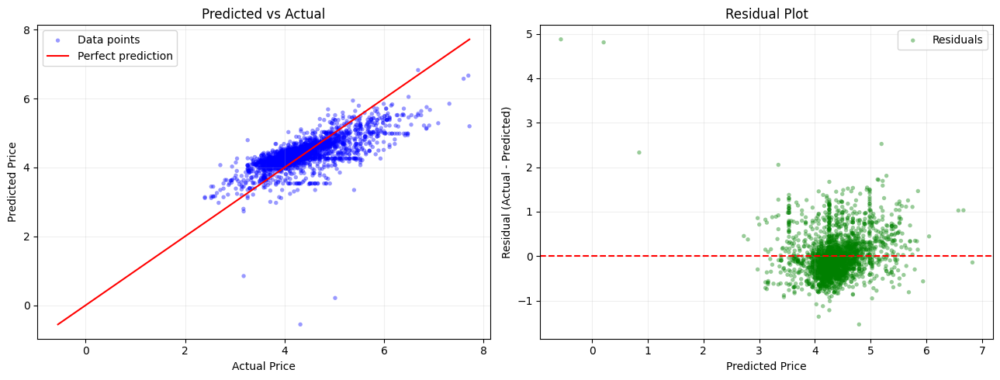

In [203]:
num_model_lasso.plot(X_test_num, y_test_num, y_pred_num_lasso)

In [204]:
plot_interactive(y_test_num, y_pred_num_lasso)

## **Multiple Linear Regression: Gradient Descent**

In this section, we implement **Multiple Linear Regression** from scratch using NumPy only (no sklearn or statsmodels for the core math).

The model is trained using **Gradient Descent**, which iteratively updates the coefficients to minimize the Mean Squared Error (MSE). We also extend the class to support **Ridge** and **Lasso** regularization as optional parameters, both defaulting to no penalty.

In [205]:
class MultipleLinearRegressionGD:

    def __init__(self, regularization=None, lambda_=0):
        """
        Initializes the MultipleLinearRegressionGD model.

        Attributes:
        -----------
        B_0            : float      — intercept (bias)
        B              : np.ndarray — weight vector [B_1, B_2, ..., B_n]
        SSE            : float      — Sum of Squared Errors
        MSE            : float      — Mean Squared Error
        cost_history   : list       — MSE recorded at each iteration
        regularization : str/None   — 'ridge', 'lasso', or None
        lambda_        : float      — penalty strength (default = 0)
        """
        self.B_0            = None
        self.B              = None
        self.SSE            = float('inf')
        self.MSE            = None
        self.cost_history   = []
        self.regularization = regularization
        self.lambda_        = lambda_


    def fit(self, X, y, learning_rate=0.01, epochs=1000, tolerance=1e-6):
        """
        Fits the model using Gradient Descent with optional regularization.

        Parameters:
        -----------
        X             : array-like, shape (m, n) — feature matrix
        y             : array-like, shape (m,)   — target vector
        learning_rate : float — step size for gradient descent
        epochs        : int   — max number of iterations
        tolerance     : float — stop early if SSE barely changes
        """
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        m, n = X.shape

        self.B_0          = 0.0
        self.B            = np.zeros(n)
        self.cost_history = []

        for _ in range(epochs):
            y_hat = self.B_0 + X @ self.B
            E = y - y_hat

            # Base gradients
            dB_0 = (-2 / m) * np.sum(E)
            dB   = (-2 / m) * (X.T @ E)

            # Add regularization penalty to dB
            if self.regularization == 'ridge':
                dB += (2 * m * self.lambda_ / m) * self.B
            elif self.regularization == 'lasso':
                dB += (self.lambda_) * np.sign(self.B)

            # Update coefficients
            self.B_0 -= learning_rate * dB_0
            self.B   -= learning_rate * dB

            # Compute SSE after update
            new_sse = np.sum((y - (self.B_0 + X @ self.B)) ** 2)

            # Penalized cost saved to history
            mse = new_sse / m
            if self.regularization == 'ridge':
                mse += self.lambda_ * np.sum(self.B ** 2)
            elif self.regularization == 'lasso':
                mse += self.lambda_ * np.sum(np.abs(self.B))

            self.cost_history.append(mse)

            # Convergence check
            if abs(new_sse - self.SSE) < tolerance:
                self.SSE = new_sse
                print(f'Converged early at epoch {_}')
                break

            self.SSE = new_sse

        self.MSE = self.SSE / m
        self.RMSE = np.sqrt(self.MSE)

        return self


    def predict(self, X):
        """
        Predicts target values for new input data.

        Parameters:
        -----------
        X : array-like, shape (m, n)

        Returns:
        --------
        np.ndarray — predicted values

        Raises:
        -------
        ValueError — if model has not been fitted yet
        """
        if self.B_0 is None or self.B is None:
            raise ValueError('The model has not been fitted yet.')

        X = np.array(X, dtype=float)
        return self.B_0 + X @ self.B


    def r2_score(self, y_true, y_pred):
        """
        Computes R² (coefficient of determination).
        R² = 1 - (SS_residual / SS_total)
        Closer to 1.0 = better fit.
        """
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return 1 - (ss_res / ss_tot)


    def plot_cost(self):
        """
        Plots the MSE cost over iterations.
        Should go down — proves gradient descent is working.
        """
        if not self.cost_history:
            raise ValueError('The model has not been fitted yet.')

        plt.figure(figsize=(9, 4))
        plt.plot(self.cost_history, color='#7F77DD', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('MSE')
        title = 'Gradient Descent (Cost over Epochs)'
        if self.regularization:
            title += f' ({self.regularization.capitalize()}, λ={self.lambda_})'
        plt.title(title)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


    def plot(self, y_true, y_pred):
        """
        Plots Predicted vs Actual values and Residuals.

        Parameters:
        -----------
        y_true : array-like — actual target values
        y_pred : array-like — predicted target values
        """
        if self.B_0 is None:
            raise ValueError('The model has not been fitted yet.')

        y_true    = np.array(y_true)
        y_pred    = np.array(y_pred)
        residuals = y_true - y_pred

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        # Plot 1: Predicted vs Actual
        axes[0].scatter(y_true, y_pred, alpha=0.4, color='blue', edgecolors='none', s=15, label='Data points')
        min_val = min(y_true.min(), y_pred.min())
        max_val = max(y_true.max(), y_pred.max())
        axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linewidth=1.5, label='Perfect prediction')
        axes[0].set_xlabel('Actual Price')
        axes[0].set_ylabel('Predicted Price')
        axes[0].set_title('Predicted vs Actual')
        axes[0].legend()
        axes[0].grid(True, alpha=0.2)

        # Plot 2: Residuals
        axes[1].scatter(y_pred, residuals, alpha=0.4, color='green', edgecolors='none', s=15, label='Residuals')
        axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
        axes[1].set_xlabel('Predicted Price')
        axes[1].set_ylabel('Residual (Actual - Predicted)')
        axes[1].set_title('Residual Plot')
        axes[1].legend()
        axes[1].grid(True, alpha=0.2)

        plt.tight_layout()
        plt.show()

print('Class defined successfully!')

Class defined successfully!


In [206]:
def plot_cost_interactive(cost_history, title="Gradient Descent Cost Over Epochs"):
    
    fig = go.Figure()

    fig.add_trace(
        go.Scatter(y=cost_history, mode='lines', name='Cost (MSE)', line=dict(width=2))
    )

    fig.update_layout(
        title=title,
        xaxis_title="Epoch",
        yaxis_title="MSE",
        hovermode="x unified"
    )

    fig.show()

## Plain Gradient Descent

In [207]:
GD_model_plain = MultipleLinearRegressionGD(regularization=None)
GD_model_plain.fit(x_train, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(GD_model_plain.SSE, 4))
print('MSE:' , round(GD_model_plain.MSE, 4))
print('RMSE:' , round(GD_model_plain.RMSE, 4))

y_pred_plain = GD_model_plain.predict(x_test)
r2_GD_plain = GD_model_plain.r2_score(np.array(y_test), y_pred_plain)
print(f'Plain GD — R²: {r2_GD_plain:.4f}')

SSE: 965.481
MSE: 0.0994
RMSE: 0.3153
Plain GD — R²: 0.7493


In [208]:
train_pred = GD_model_plain.predict(x_train)
test_pred  = GD_model_plain.predict(x_test)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Gradient Descent Plain:")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Gradient Descent Plain:
Train MSE (original scale): 6,361.32
Test MSE  (original scale): 6,957.78


### **Gradient Descent Convergence Plot**

This plot shows how the loss function (MSE) decreases over training iterations.

- A decreasing curve indicates that the model is learning effectively.
- Convergence (flattening of the curve) shows that the model has reached optimal parameters.
- If the curve fluctuates, it may indicate a high learning rate.

This visualization confirms that the Gradient Descent implementation is working correctly and converging to a minimum.

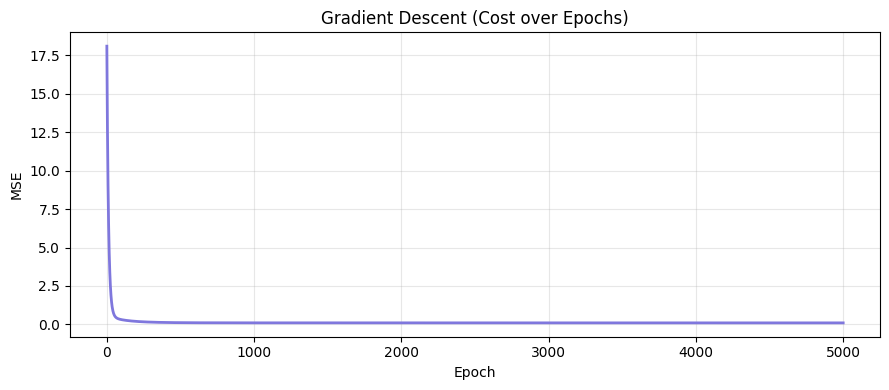

In [209]:
GD_model_plain.plot_cost()

In [210]:
plot_cost_interactive(GD_model_plain.cost_history, "Plain GD - Cost Over Epochs")

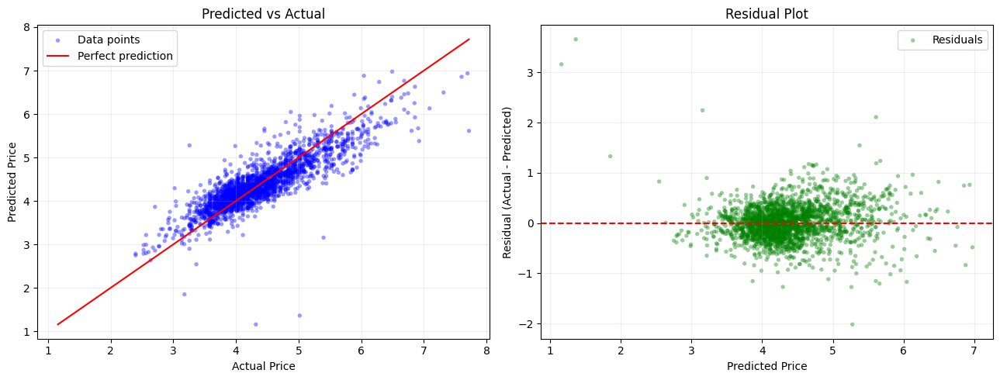

In [211]:
GD_model_plain.plot(y_test, y_pred_plain)

In [212]:
plot_interactive(y_test, y_pred_plain)

## Ridge Regression (Gradient Descent + L2)

In [213]:
GD_model_ridge = MultipleLinearRegressionGD(regularization='ridge', lambda_=0.01)
GD_model_ridge.fit(x_train, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(GD_model_ridge.SSE, 4))
print('MSE:' , round(GD_model_ridge.MSE, 4))
print('RMSE:' , round(GD_model_ridge.RMSE, 4))

y_pred_ridge = GD_model_ridge.predict(x_test)
r2_GD_ridge = GD_model_ridge.r2_score(np.array(y_test), y_pred_ridge)
print(f'Ridge GD — R²: {r2_GD_ridge:.4f}')

SSE: 963.9726
MSE: 0.0993
RMSE: 0.3151
Ridge GD — R²: 0.7483


In [214]:
train_pred = GD_model_ridge.predict(x_train)
test_pred  = GD_model_ridge.predict(x_test)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Gradient Descent Ridge (λ=0.01):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Gradient Descent Ridge (λ=0.01):
Train MSE (original scale): 6,396.86
Test MSE  (original scale): 7,169.52


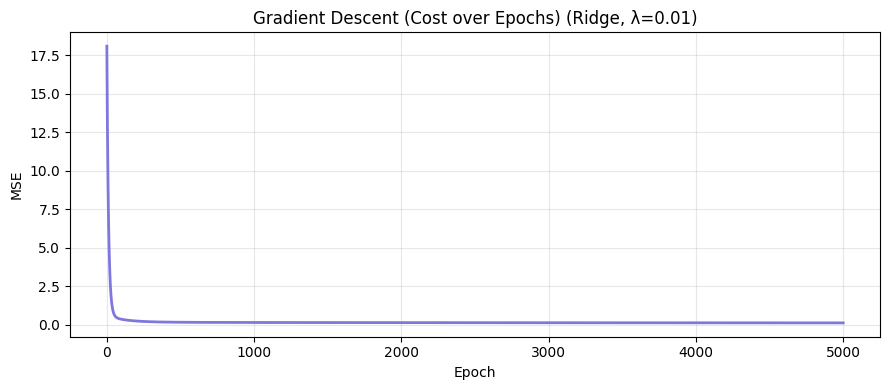

In [215]:
GD_model_ridge.plot_cost()

In [216]:
plot_cost_interactive(GD_model_ridge.cost_history, "Ridge GD - Cost Over Epochs")

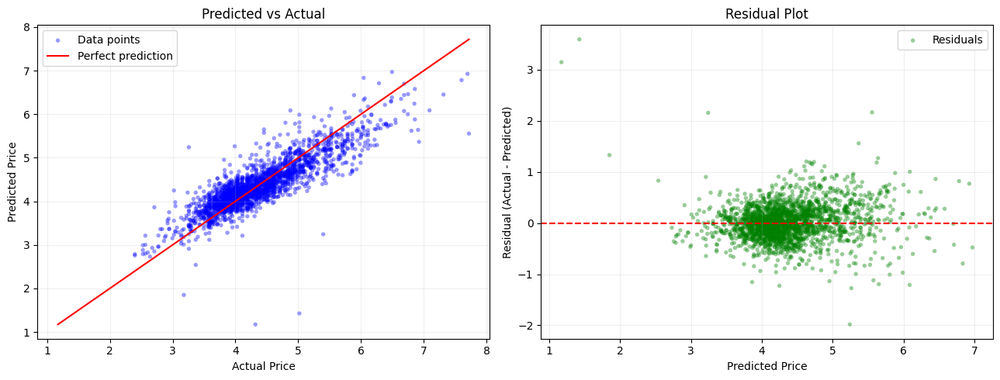

In [217]:
GD_model_ridge.plot(y_test, y_pred_ridge)

In [218]:
plot_interactive(y_test,y_pred_ridge)

## Lasso Regression (Gradient Descent + L1)

In [219]:
GD_model_lasso = MultipleLinearRegressionGD(regularization='lasso', lambda_=0.01)
GD_model_lasso.fit(x_train, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(GD_model_lasso.SSE, 4))
print('MSE:' , round(GD_model_lasso.MSE, 4))
print('RMSE:' , round(GD_model_lasso.RMSE, 4))

y_pred_lasso = GD_model_lasso.predict(x_test)
r2_GD_lasso = GD_model_lasso.r2_score(np.array(y_test), y_pred_lasso)
print(f'Lasso GD — R²: {r2_GD_lasso:.4f}')

Converged early at epoch 3722
SSE: 973.4717
MSE: 0.1003
RMSE: 0.3166
Lasso GD — R²: 0.7464


In [220]:
train_pred = GD_model_lasso.predict(x_train)
test_pred  = GD_model_lasso.predict(x_test)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Gradient Descent Lasso (λ=0.01):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Gradient Descent Lasso (λ=0.01):
Train MSE (original scale): 6,379.59
Test MSE  (original scale): 7,101.72


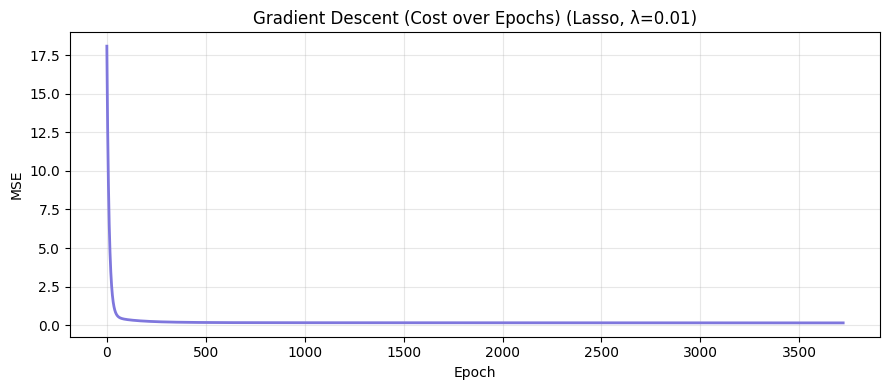

In [221]:
GD_model_lasso.plot_cost()

In [222]:
plot_cost_interactive(GD_model_lasso.cost_history, "Lasso GD - Cost Over Epochs")

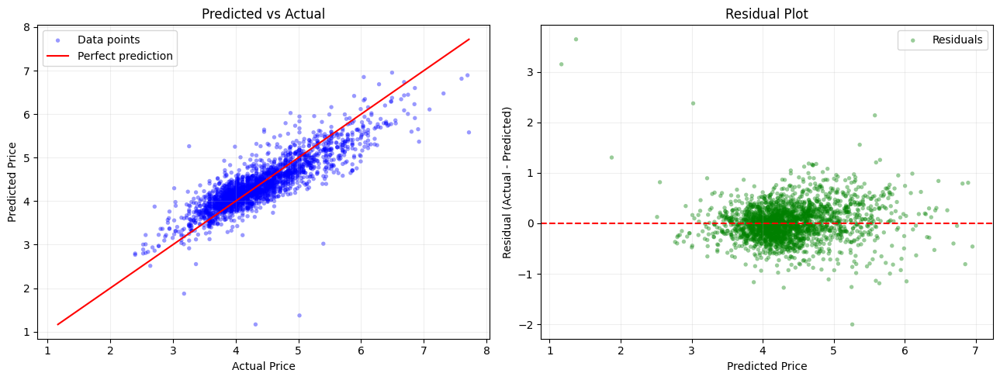

In [223]:
GD_model_lasso.plot(y_test,y_pred_lasso)

In [224]:
plot_interactive(y_test,y_pred_lasso)

# **Domain Knowledge Model**

Based on EDA findings and knowledge of the Bengaluru real estate market,
three features are selected as the primary price drivers:
- **total_sqft** : property size is the strongest predictor confirmed by the scatter plots and heatmap
- **bath** : number of bathrooms showed moderate positive correlation with price
- **location_enc** : location is the most well-known driver of property value in Bengaluru,
  captured here through target encoding

`balcony`, `Number_of_rooms`, `area_type`, and `availability` are excluded
as they showed weaker relationships with price in EDA.

In [225]:
domain_cols = ['total_sqft', 'bath', 'location_enc']

x_train_domain = x_train[domain_cols].values
x_test_domain  = x_test[domain_cols].values

## Plain (Domain Knowledge)

In [226]:
domain_model = MultipleLinearRegressionGD(regularization=None)
domain_model.fit(x_train_domain, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(domain_model.SSE, 4))
print('MSE:' , round(domain_model.MSE, 4))
print('RMSE:' , round(domain_model.RMSE, 4))

y_pred_domain = domain_model.predict(x_test_domain)
r2_GD_domain  = domain_model.r2_score(np.array(y_test), y_pred_domain)
print(f'Domain Plain — R²: {r2_GD_domain:.4f}')

Converged early at epoch 691
SSE: 1095.6157
MSE: 0.1128
RMSE: 0.3359
Domain Plain — R²: 0.7067


In [227]:
train_pred = domain_model.predict(x_train_domain)
test_pred  = domain_model.predict(x_test_domain)

train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Domain Knowledge Plain:")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Domain Knowledge Plain:
Train MSE (original scale): 7,220.46
Test MSE  (original scale): 8,377.17


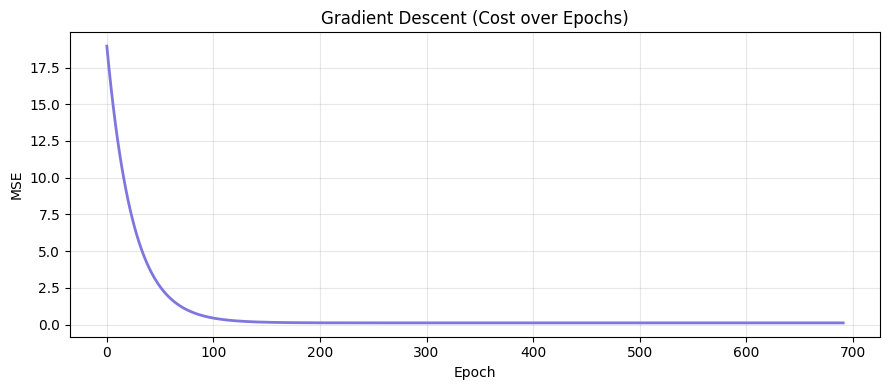

In [228]:
domain_model.plot_cost()

In [229]:
plot_cost_interactive(domain_model.cost_history, "Plain (Domain Knowledge) - Cost Over Epochs")

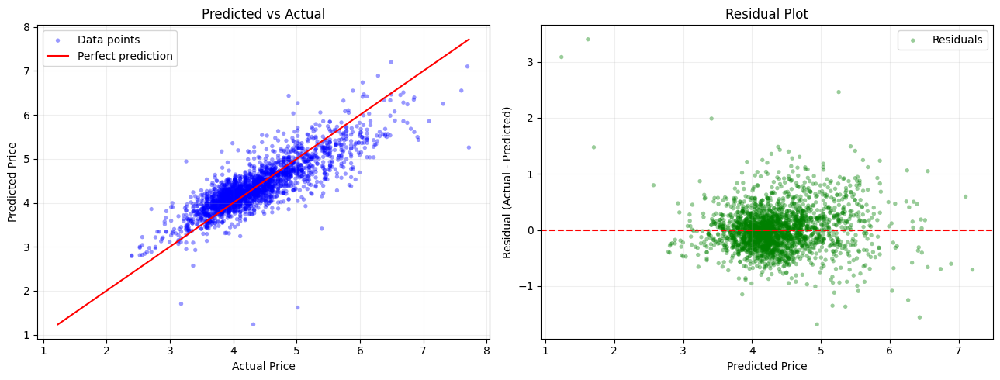

In [230]:
domain_model.plot(y_test, y_pred_domain)

In [231]:
plot_interactive(y_test,y_pred_domain)

## Ridge Regression (Domain Knowledge + L2)

In [232]:
domain_model_ridge = MultipleLinearRegressionGD(regularization='ridge', lambda_=0.01)
domain_model_ridge.fit(x_train_domain, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(domain_model_ridge.SSE, 4))
print('MSE:' , round(domain_model_ridge.MSE, 4))
print('RMSE:' , round(domain_model_ridge.RMSE, 4))

y_pred_domain_ridge = domain_model_ridge.predict(x_test_domain)
r2_domain_ridge     = domain_model_ridge.r2_score(np.array(y_test), y_pred_domain_ridge)
print(f'Domain Ridge — R²: {r2_domain_ridge:.4f}')

Converged early at epoch 937
SSE: 1095.7261
MSE: 0.1129
RMSE: 0.3359
Domain Ridge — R²: 0.7065


In [233]:
train_pred = domain_model_ridge.predict(x_train_domain)
test_pred  = domain_model_ridge.predict(x_test_domain)

train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Domain Knowledge Ridge (λ=0.01):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Domain Knowledge Ridge (λ=0.01):
Train MSE (original scale): 7,209.76
Test MSE  (original scale): 8,406.34


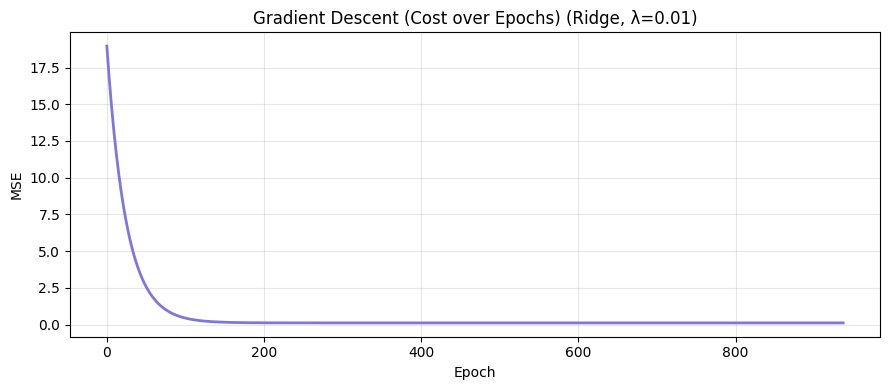

In [234]:
domain_model_ridge.plot_cost()

In [235]:
plot_cost_interactive(domain_model_ridge.cost_history, "Ridge (Domain Knowledge) - Cost Over Epochs")

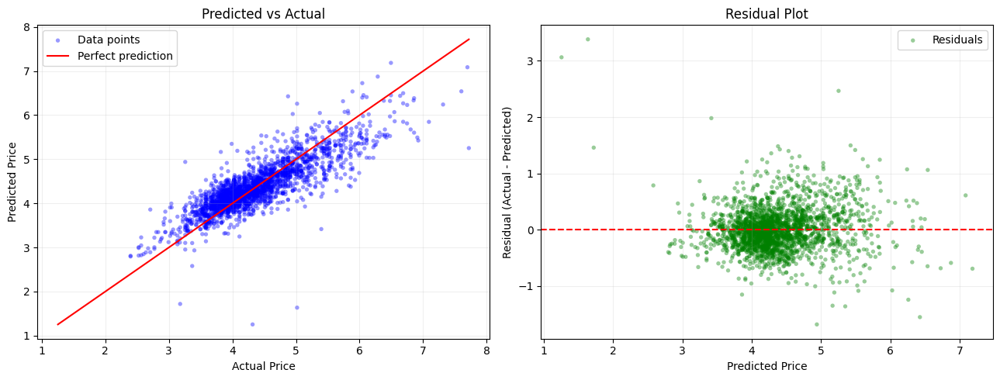

In [236]:
domain_model_ridge.plot(y_test, y_pred_domain_ridge)

In [237]:
plot_interactive(y_test, y_pred_domain_ridge)

## Lasso Regression (Domain Knowledge + L1)

In [238]:
domain_model_lasso = MultipleLinearRegressionGD(regularization='lasso', lambda_=0.01)
domain_model_lasso.fit(x_train_domain, y_train, learning_rate=0.01, epochs=5000)
print('SSE:' , round(domain_model_lasso.SSE, 4))
print('MSE:' , round(domain_model_lasso.MSE, 4))
print('RMSE:' , round(domain_model_lasso.RMSE, 4))

y_pred_domain_lasso = domain_model_lasso.predict(x_test_domain)
r2_domain_lasso     = domain_model_lasso.r2_score(np.array(y_test), y_pred_domain_lasso)
print(f'Domain Lasso — R²: {r2_domain_lasso:.4f}')

Converged early at epoch 546
SSE: 1096.0068
MSE: 0.1129
RMSE: 0.336
Domain Lasso — R²: 0.7062


In [239]:
train_pred = domain_model_lasso.predict(x_train_domain)
test_pred  = domain_model_lasso.predict(x_test_domain)

train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original = np.expm1(y_train)
y_test_original  = np.expm1(y_test)

train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Domain Knowledge Lasso (λ=0.01):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Domain Knowledge Lasso (λ=0.01):
Train MSE (original scale): 7,190.41
Test MSE  (original scale): 8,425.05


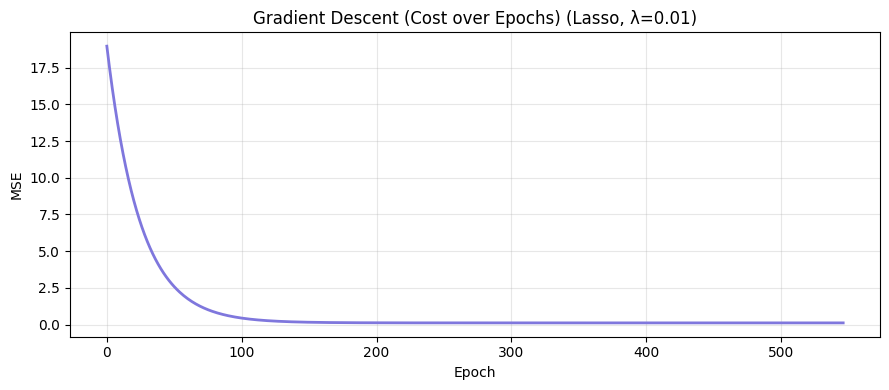

In [240]:
domain_model_lasso.plot_cost()

In [241]:
plot_cost_interactive(domain_model_lasso.cost_history, "Lasso (Domain Knowledge) - Cost Over Epochs")

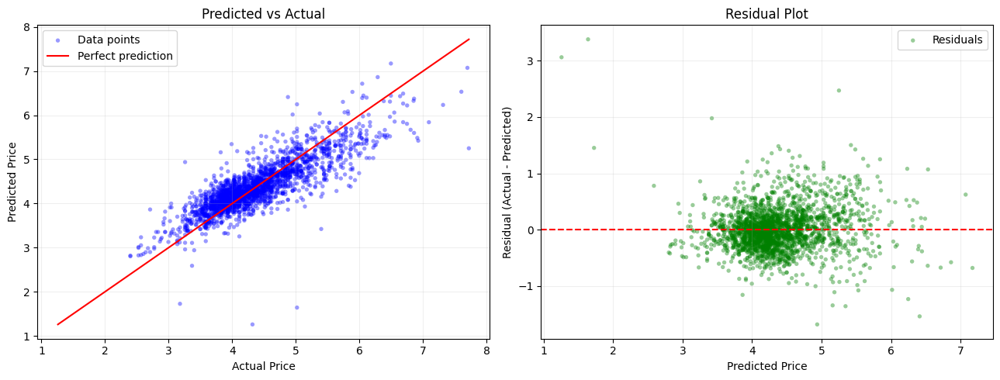

In [242]:
domain_model_lasso.plot(y_test, y_pred_domain_lasso)

In [243]:
plot_interactive(y_test,y_pred_domain_lasso)

# **Simple Linear Regression: Statistical View**

In this section, we implement **Simple Linear Regression** from scratch using NumPy, taking a purely **statistical approach** based on maximum likelihood estimation under the assumption of normally distributed errors. We derive the OLS estimator from the likelihood function and also extend the class to support **Ridge** and **Lasso** regularization as optional parameters (both defaulting to no penalty).

This **probabilistic perspective** emphasizes model assumptions, error distribution, and statistical properties of the estimators.

In [244]:
class SimpleLinearRegressionStatistical:
    """
    Simple Linear Regression — Statistical (Closed-Form) View.
    Derives B_1 via SXY/SXX (OLS), with optional Ridge or Lasso regularization.
    Mirrors the interface of the Numerical and GD views.
    """

    def __init__(self, regularization=None, lambda_=0.0):
        """
        Parameters
        ----------
        regularization : None | 'ridge' | 'lasso'
        lambda_        : regularization strength (ignored when regularization=None)
        """
        self.regularization = regularization
        self.lambda_        = lambda_
        self.B_0            = None
        self.B_1            = None
        self.SSE            = None
        self.MSE            = None
        self.RMSE           = None

    def fit(self, x, y):
        X = np.asarray(x, dtype=float).flatten()
        y = np.asarray(y, dtype=float)
        n = len(X)

        x_bar = X.mean()
        y_bar = y.mean()

        SXX = np.sum(X ** 2) - n * x_bar ** 2
        SXY = np.sum(X * y)  - n * x_bar * y_bar

        # OLS slope
        B_1_ols = SXY / SXX

        if self.regularization == 'ridge' and self.lambda_ > 0:
            # Ridge
            self.B_1 = SXY / (SXX + n * self.lambda_)

        elif self.regularization == 'lasso' and self.lambda_ > 0:
            # Lasso
            threshold = (n * self.lambda_) / (2 * SXX)
            self.B_1  = np.sign(B_1_ols) * max(abs(B_1_ols) - threshold, 0.0)

        else:
            # Plain OLS
            self.B_1 = B_1_ols

        # Intercept
        self.B_0 = y_bar - self.B_1 * x_bar

        # Metrics
        y_hat    = self.predict(X)
        self.SSE  = float(np.sum((y - y_hat) ** 2))
        self.MSE  = self.SSE / n
        self.RMSE = np.sqrt(self.MSE)

        return self

    def predict(self, x):
        if self.B_0 is None:
            raise ValueError("Model has not been fitted yet.")
        x = np.asarray(x, dtype=float).flatten()
        return self.B_0 + self.B_1 * x

    def r2_score(self, y_true, y_pred):
        y_true = np.asarray(y_true, dtype=float)
        y_pred = np.asarray(y_pred, dtype=float)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)
        if ss_tot == 0:
            return 0.0
        return 1 - ss_res / ss_tot

    def plot(self, y_true, y_pred):
        """
        Two-panel diagnostic plot (same layout as GD view):
          Left  — Predicted vs Actual  (with perfect-prediction line)
          Right — Residual Plot        (residuals vs predicted)
        """
        if self.B_0 is None:
            raise ValueError("Model has not been fitted yet.")

        y_true    = np.asarray(y_true, dtype=float)
        y_pred    = np.asarray(y_pred, dtype=float)
        residuals = y_true - y_pred

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        # Plot 1: Predicted vs Actual
        axes[0].scatter(y_true, y_pred, alpha=0.4, color='blue', edgecolors='none', s=15, label='Data points')
        min_val = min(y_true.min(), y_pred.min())
        max_val = max(y_true.max(), y_pred.max())
        axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linewidth=1.5, label='Perfect prediction')
        axes[0].set_xlabel('Actual Price')
        axes[0].set_ylabel('Predicted Price')
        axes[0].set_title('Predicted vs Actual')
        axes[0].legend()
        axes[0].grid(True, alpha=0.2)

        # Plot 2: Residuals
        axes[1].scatter(y_pred, residuals, alpha=0.4, color='green', edgecolors='none', s=15, label='Residuals')
        axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
        axes[1].set_xlabel('Predicted Price')
        axes[1].set_ylabel('Residual (Actual - Predicted)')
        axes[1].set_title('Residual Plot')
        axes[1].legend()
        axes[1].grid(True, alpha=0.2)

        plt.tight_layout()
        plt.show()

print('Class defined successfully!')

Class defined successfully!


## Plain OLS (Statistical)

In [245]:
stat_model_plain = SimpleLinearRegressionStatistical(regularization=None)
stat_model_plain.fit(X_train_num, y_train_num)
print('SSE: ', round(stat_model_plain.SSE,  4))
print('MSE: ', round(stat_model_plain.MSE,  4))
print('RMSE:', round(stat_model_plain.RMSE, 4))

y_pred_stat_plain = stat_model_plain.predict(X_test_num)
r2_stat_plain = stat_model_plain.r2_score(np.array(y_test_num), y_pred_stat_plain)
print(f'Plain Statistical — R²: {r2_stat_plain:.4f}')

SSE:  2060.9062
MSE:  0.2123
RMSE: 0.4607
Plain Statistical — R²: 0.5270


In [246]:
train_pred = stat_model_plain.predict(X_train_num)
test_pred  = stat_model_plain.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original    = np.expm1(y_train_num)
y_test_original     = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Statistical Plain:")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Statistical Plain:
Train MSE (original scale): 17,044.40
Test MSE  (original scale): 9,858.82


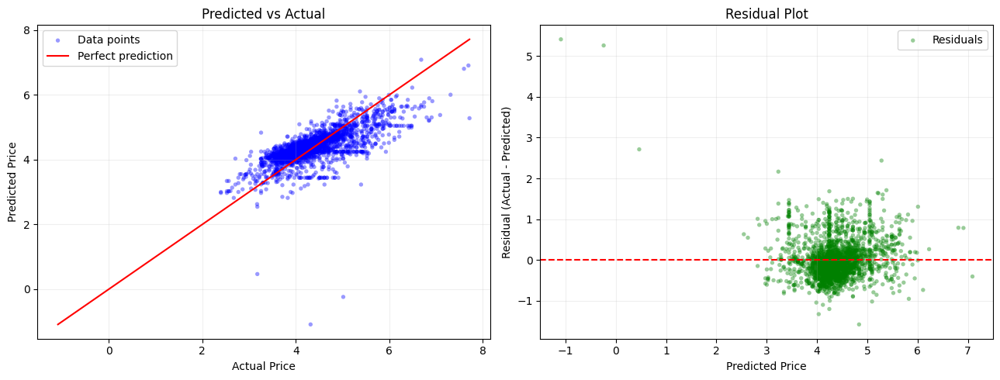

In [247]:
stat_model_plain.plot(y_test_num, y_pred_stat_plain)

In [248]:
plot_interactive(y_test_num, y_pred_stat_plain)

## Ridge Regression (Statistical + L2)

In [249]:
stat_model_ridge = SimpleLinearRegressionStatistical(regularization='ridge', lambda_=0.05)
stat_model_ridge.fit(X_train_num, y_train_num)
print('SSE: ', round(stat_model_ridge.SSE,  4))
print('MSE: ', round(stat_model_ridge.MSE,  4))
print('RMSE:', round(stat_model_ridge.RMSE, 4))

y_pred_stat_ridge = stat_model_ridge.predict(X_test_num)
r2_stat_ridge = stat_model_ridge.r2_score(np.array(y_test_num), y_pred_stat_ridge)
print(f'Ridge Statistical — R²: {r2_stat_ridge:.4f}')

SSE:  2066.7345
MSE:  0.2129
RMSE: 0.4614
Ridge Statistical — R²: 0.5259


In [250]:
train_pred = stat_model_ridge.predict(X_train_num)
test_pred  = stat_model_ridge.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original    = np.expm1(y_train_num)
y_test_original     = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Statistical Ridge (λ=0.05):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Statistical Ridge (λ=0.05):
Train MSE (original scale): 14,935.56
Test MSE  (original scale): 10,303.40


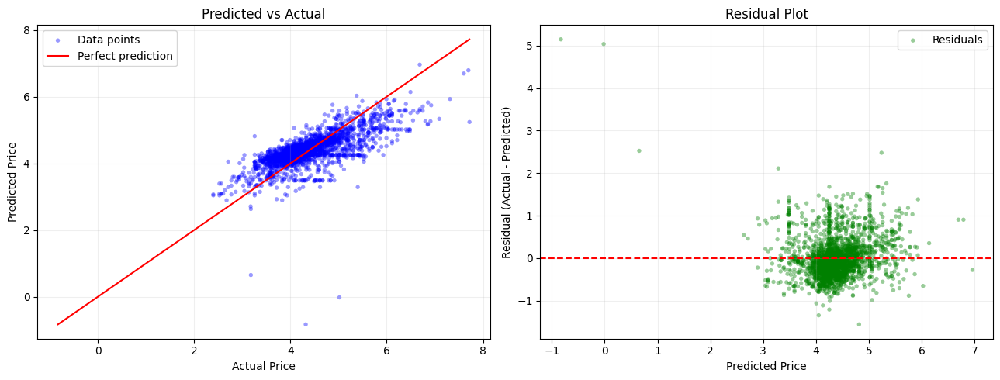

In [251]:
stat_model_ridge.plot(y_test_num, y_pred_stat_ridge)

In [252]:
plot_interactive(y_test_num, y_pred_stat_ridge)

## Lasso Regression (Statistical + L1)

In [253]:
stat_model_lasso = SimpleLinearRegressionStatistical(regularization='lasso', lambda_=0.1)
stat_model_lasso.fit(X_train_num, y_train_num)
print('SSE: ', round(stat_model_lasso.SSE,  4))
print('MSE: ', round(stat_model_lasso.MSE,  4))
print('RMSE:', round(stat_model_lasso.RMSE, 4))

y_pred_stat_lasso = stat_model_lasso.predict(X_test_num)
r2_stat_lasso = stat_model_lasso.r2_score(np.array(y_test_num), y_pred_stat_lasso)
print(f'Lasso Statistical — R²: {r2_stat_lasso:.4f}')

SSE:  2085.1787
MSE:  0.2148
RMSE: 0.4634
Lasso Statistical — R²: 0.5222


In [254]:
train_pred = stat_model_lasso.predict(X_train_num)
test_pred  = stat_model_lasso.predict(X_test_num)

# Return to original price scale
train_pred_original = np.expm1(train_pred)
test_pred_original  = np.expm1(test_pred)

y_train_original    = np.expm1(y_train_num)
y_test_original     = np.expm1(y_test_num)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Calculate errors on original scale
train_mse = mse(y_train_original, train_pred_original)
test_mse  = mse(y_test_original, test_pred_original)

print(f"\nMetrics for Statistical Lasso (λ=0.1):")
print(f"Train MSE (original scale): {train_mse:,.2f}")
print(f"Test MSE  (original scale): {test_mse:,.2f}")


Metrics for Statistical Lasso (λ=0.1):
Train MSE (original scale): 13,669.41
Test MSE  (original scale): 10,792.34


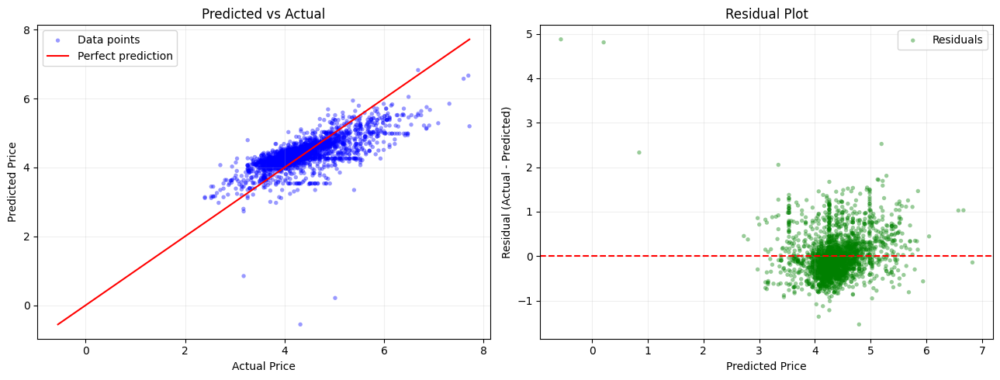

In [255]:
stat_model_lasso.plot(y_test_num, y_pred_stat_lasso)

In [256]:
plot_interactive(y_test_num, y_pred_stat_lasso)

# **Model Comparison**
The table below summarises the R² and Adjusted R² scores for each variant.

In [257]:
n_train = x_train.shape[0]
p_mlr    = x_train.shape[1]
p_slr    = 1
p_domain = 3

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

comparison = pd.DataFrame({
    'Model'         : ['Numerical View Plain', 'Numerical View Ridge', 'Numerical View Lasso',
                       'Gradient Descent Plain', 'Gradient Descent Ridge', 'Gradient Descent Lasso',
                       'Domain Knowledge Plain', 'Domain Knowledge Ridge', 'Domain Knowledge Lasso',
                       'Statistical View Plain', 'Statistical View Ridge', 'Statistical View Lasso'],
    'Type'          : ['SLR', 'SLR', 'SLR', 'MLR', 'MLR', 'MLR', 'MLR', 'MLR', 'MLR', 'SLR', 'SLR', 'SLR'],
    'Regularization': ['None', 'L2', 'L1', 'None', 'L2', 'L1', 'None', 'L2', 'L1', 'None', 'L2', 'L1'],
    '# Predictors'  : [p_slr, p_slr, p_slr, p_mlr, p_mlr, p_mlr, p_domain, p_domain, p_domain, p_slr, p_slr, p_slr],
    'R²'            : [round(r2_num_plain, 4), round(r2_num_ridge, 4), round(r2_num_lasso, 4),
                       round(r2_GD_plain, 4), round(r2_GD_ridge, 4), round(r2_GD_lasso, 4),
                       round(r2_GD_domain, 4), round(r2_domain_ridge, 4), round(r2_domain_lasso, 4),
                       round(r2_stat_plain, 4), round(r2_stat_ridge, 4), round(r2_stat_lasso, 4)],
    'Adjusted R²'   : [round(adjusted_r2(r2_num_plain, n_train, p_slr), 4),
                       round(adjusted_r2(r2_num_ridge, n_train, p_slr), 4),
                       round(adjusted_r2(r2_num_lasso, n_train, p_slr), 4),
                       round(adjusted_r2(r2_GD_plain, n_train, p_mlr), 4),
                       round(adjusted_r2(r2_GD_ridge, n_train, p_mlr), 4),
                       round(adjusted_r2(r2_GD_lasso, n_train, p_mlr), 4),
                       round(adjusted_r2(r2_GD_domain, n_train, p_domain), 4),
                       round(adjusted_r2(r2_domain_ridge, n_train, p_domain), 4),
                       round(adjusted_r2(r2_domain_lasso, n_train, p_domain), 4),
                       round(adjusted_r2(r2_stat_plain, n_train, p_slr), 4),
                       round(adjusted_r2(r2_stat_ridge, n_train, p_slr), 4),
                       round(adjusted_r2(r2_stat_lasso, n_train, p_slr), 4)]
})
comparison

,Model,Type,Regularization,# Predictors,R²,Adjusted R²
0,Numerical View Plain,SLR,None,1,0.5270,0.5270
1,Numerical View Ridge,SLR,L2,1,0.5259,0.5258
2,Numerical View Lasso,SLR,L1,1,0.5222,0.5221
3,Gradient Descent Plain,MLR,None,11,0.7493,0.7490
4,Gradient Descent Ridge,MLR,L2,11,0.7483,0.7480
5,Gradient Descent Lasso,MLR,L1,11,0.7464,0.7461
6,Domain Knowledge Plain,MLR,None,3,0.7067,0.7066
7,Domain Knowledge Ridge,MLR,L2,3,0.7065,0.7064
8,Domain Knowledge Lasso,MLR,L1,3,0.7062,0.7061
9,Statistical View Plain,SLR,None,1,0.5270,0.5270


## **Coefficient Comparison Across Models**

This code compares the learned coefficients from three regression models: `Simple Linear Regression (SLR)`, `Multiple Linear Regression (MLR)`, and a `Domain-based model`.

First, the feature sets for each model are defined. Then, the coefficients (weights) are extracted from each trained model:

- SLR uses a single coefficient (slope).
- MLR uses multiple coefficients from the gradient descent model.
- The Domain model uses a selected subset of important features.

Since each model has a different number of coefficients, padding with NaN is applied to align their lengths for fair comparison.

A DataFrame is then created to store feature names and their corresponding coefficients across all models.

Finally, a grouped bar chart is plotted to visually compare how each feature contributes differently in each model.

### **Key Observations:**
1) **SLR (Blue) :**
- Only total_sqft is used.
- It has a relatively strong positive coefficient.
- This means area is a strong predictor of price.

2) **MLR (Orange) :**
- Shows many features with different impacts.
- Some area types (like Super built-up, Plot area) have high coefficients.
- Availability features also have strong influence.
- This model captures more complex relationships.

3) **Domain Model (Green) :**
- Uses only selected meaningful features.
- Coefficients are more balanced and interpretable.
- Focuses mainly on:
    - total_sqft
    - bath
    - balcony / location_enc

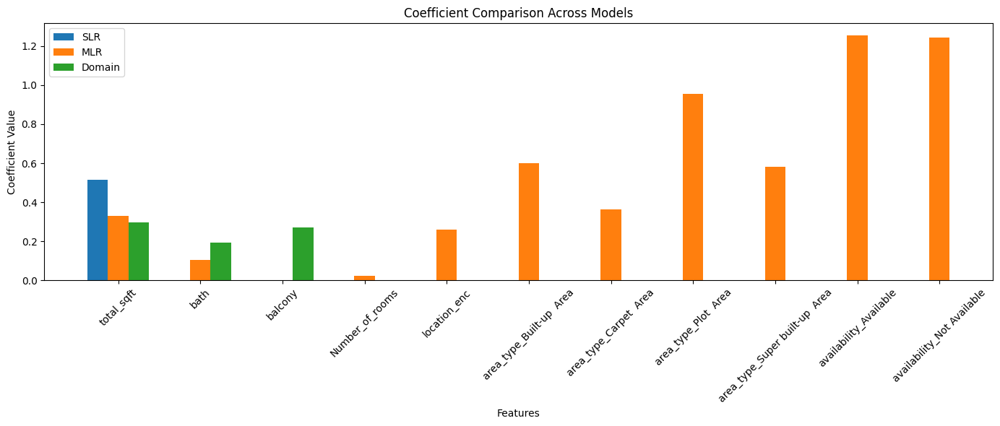

In [258]:
slr_features = ['total_sqft']
mlr_features = list(x_train.columns) 
domain_features = ['total_sqft', 'bath', 'location_enc']

slr_vals = np.array([num_model_plain.a1])
mlr_vals = GD_model_plain.B
domain_vals = domain_model.B

max_len = max(len(slr_vals), len(mlr_vals), len(domain_vals))
def pad(arr, length):
    return list(arr) + [np.nan] * (length - len(arr))
slr_vals = pad(slr_vals, max_len)
mlr_vals = pad(mlr_vals, max_len)
domain_vals = pad(domain_vals, max_len)

feature_names = mlr_features[:max_len] 
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'SLR': slr_vals,
    'MLR': mlr_vals,
    'Domain': domain_vals
})

x = np.arange(len(coef_df['Feature']))
width = 0.25

plt.figure(figsize=(14,6))

plt.bar(x - width, coef_df['SLR'], width, label='SLR')
plt.bar(x, coef_df['MLR'], width, label='MLR')
plt.bar(x + width, coef_df['Domain'], width, label='Domain')

plt.xticks(x, coef_df['Feature'], rotation=45)
plt.title("Coefficient Comparison Across Models")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.legend()
plt.tight_layout()
plt.show()

In [259]:
slr_features = ['total_sqft']
mlr_features = list(x_train.columns)
domain_features = ['total_sqft', 'bath', 'location_enc']

slr_vals = np.array([num_model_plain.a1])
mlr_vals = GD_model_plain.B
domain_vals = domain_model.B

max_len = max(len(slr_vals), len(mlr_vals), len(domain_vals))

def pad(arr, length):
    return list(arr) + [np.nan] * (length - len(arr))

slr_vals = pad(slr_vals, max_len)
mlr_vals = pad(mlr_vals, max_len)
domain_vals = pad(domain_vals, max_len)

feature_names = mlr_features[:max_len]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'SLR': slr_vals,
    'MLR': mlr_vals,
    'Domain': domain_vals
})

# Plotly grouped bar chart
fig = go.Figure()

fig.add_trace(go.Bar(
    x=coef_df['Feature'],
    y=coef_df['SLR'],
    name='SLR'
))

fig.add_trace(go.Bar(
    x=coef_df['Feature'],
    y=coef_df['MLR'],
    name='MLR'
))

fig.add_trace(go.Bar(
    x=coef_df['Feature'],
    y=coef_df['Domain'],
    name='Domain'
))

fig.update_layout(
    title="Coefficient Comparison Across Models",
    xaxis_title="Features",
    yaxis_title="Coefficient Value",
    barmode='group'
)

fig.show()

#### **Overall Insight:**
- `MLR` has the most detailed representation of feature effects.
- `SLR` is simple but limited (only one variable).
- `Domain model` is a trade-off between simplicity and interpretability.

Adding more features increases complexity, but not all features contribute equally to prediction.


---

## **Residual Plot**

A residual plot is used to evaluate the performance of a regression model by analyzing the errors between the actual and predicted values.

The residual is defined as:

- `Residual = Actual Value − Predicted Value`

In this project, interactive residual plots were created using `Plotly` to visualize model performance across different regression approaches (Simple Linear Regression, Multiple Linear Regression, Ridge, and Lasso in different views).

In [260]:
def residual_plot_interactive(y_true, y_pred, title="Residual Plot"):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    residuals = y_true - y_pred

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=y_pred,
        y=residuals,
        mode='markers',
        name='Residuals',
        opacity=0.5
    ))

    fig.add_hline(y=0, line_dash="dash", line_color="red")

    fig.update_layout(
        title=title,
        xaxis_title="Predicted Values",
        yaxis_title="Residuals"
    )

    fig.show()

### **1. Numerical Models**

In [261]:
residual_plot_interactive(y_test_num, y_pred_num_plain, "Numerical - Plain Residuals")
residual_plot_interactive(y_test_num, y_pred_num_ridge, "Numerical - Ridge Residuals")
residual_plot_interactive(y_test_num, y_pred_num_lasso, "Numerical - Lasso Residuals")

---

### **2. Gradient Descent**

In [262]:
residual_plot_interactive(y_test, y_pred_plain, "GD - Plain Residuals")
residual_plot_interactive(y_test, y_pred_ridge, "GD - Ridge Residuals")
residual_plot_interactive(y_test, y_pred_lasso, "GD - Lasso Residuals")

---

### **3. Domain Knowledge Models**

In [263]:
residual_plot_interactive(y_test, y_pred_domain, "Domain - Plain Residuals")
residual_plot_interactive(y_test, y_pred_domain_ridge, "Domain - Ridge Residuals")
residual_plot_interactive(y_test, y_pred_domain_lasso, "Domain - Lasso Residuals")

---

### **4. Statistical Models**

In [264]:
residual_plot_interactive(y_test_num, y_pred_stat_plain, "Statistical - Plain Residuals")
residual_plot_interactive(y_test_num, y_pred_stat_ridge, "Statistical - Ridge Residuals")
residual_plot_interactive(y_test_num, y_pred_stat_lasso, "Statistical - Lasso Residuals")